<a href="https://colab.research.google.com/github/mini-KK27926/User_churn_prediction/blob/main/%D0%9F%D1%80%D0%B5%D0%B4%D1%81%D0%BA%D0%B0%D0%B7%D0%B0%D0%BD%D0%B8%D0%B5_%D0%BE%D1%82%D1%82%D0%BE%D0%BA%D0%B0_%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D0%B5%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Будем использовать метрику ROC-AUC для оценки качества модели

In [ ]:
from sklearn.metrics import roc_auc_score

y_true = [
    0,
    1,
    1,
    0,
    1
]

y_predictions = [
    0.1,
    0.9,
    0.4,
    0.6,
    0.61
]

roc_auc_score(y_true, y_predictions)

np.float64(0.8333333333333333)

# Первая часть. Исследование

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
!gdown 1ERwQ5odiK1Zvi1LtjpkzCMUswYsAX8_K  # train.csv
!gdown 1fGw_-RFwvn_LEdt91Jq-7A-wzG6mmH8r  # test.csv
!gdown 199Mt4OYZNaelT83U-HGDsEYs2YcUGQ6y  # submission.csv

Downloading...
From: https://drive.google.com/uc?id=1ERwQ5odiK1Zvi1LtjpkzCMUswYsAX8_K
To: /content/train.csv
100% 664k/664k [00:00<00:00, 18.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1fGw_-RFwvn_LEdt91Jq-7A-wzG6mmH8r
To: /content/test.csv
100% 218k/218k [00:00<00:00, 62.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=199Mt4OYZNaelT83U-HGDsEYs2YcUGQ6y
To: /content/submission.csv
100% 14.7k/14.7k [00:00<00:00, 27.7MB/s]


In [ ]:
data = pd.read_csv('./train.csv')

In [ ]:
# Числовые признаки
num_cols = [
    'ClientPeriod',
    'MonthlySpending',
    'TotalSpent'
]

# Категориальные признаки
cat_cols = [
    'Sex',
    'IsSeniorCitizen',
    'HasPartner',
    'HasChild',
    'HasPhoneService',
    'HasMultiplePhoneNumbers',
    'HasInternetService',
    'HasOnlineSecurityService',
    'HasOnlineBackup',
    'HasDeviceProtection',
    'HasTechSupportAccess',
    'HasOnlineTV',
    'HasMovieSubscription',
    'HasContractPhone',
    'IsBillingPaperless',
    'PaymentMethod'
]

feature_cols = num_cols + cat_cols
target_col = 'Churn'

Для начала оценим датасет визуально

In [ ]:
data.head()

,ClientPeriod,MonthlySpending,TotalSpent,Sex,IsSeniorCitizen,HasPartner,HasChild,HasPhoneService,HasMultiplePhoneNumbers,HasInternetService,HasOnlineSecurityService,HasOnlineBackup,HasDeviceProtection,HasTechSupportAccess,HasOnlineTV,HasMovieSubscription,HasContractPhone,IsBillingPaperless,PaymentMethod,Churn
0,55,19.50,1026.35,Male,0,Yes,Yes,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,0
1,72,25.85,1872.2,Male,0,Yes,No,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Credit card (automatic),0
2,1,75.90,75.9,Male,0,No,No,Yes,No,Fiber optic,No,No,No,Yes,No,No,Month-to-month,Yes,Electronic check,1
3,32,79.30,2570,Female,1,Yes,No,Yes,Yes,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Mailed check,0
4,60,115.25,6758.45,Female,0,Yes,Yes,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5282 entries, 0 to 5281
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ClientPeriod              5282 non-null   int64  
 1   MonthlySpending           5282 non-null   float64
 2   TotalSpent                5282 non-null   object 
 3   Sex                       5282 non-null   object 
 4   IsSeniorCitizen           5282 non-null   int64  
 5   HasPartner                5282 non-null   object 
 6   HasChild                  5282 non-null   object 
 7   HasPhoneService           5282 non-null   object 
 8   HasMultiplePhoneNumbers   5282 non-null   object 
 9   HasInternetService        5282 non-null   object 
 10  HasOnlineSecurityService  5282 non-null   object 
 11  HasOnlineBackup           5282 non-null   object 
 12  HasDeviceProtection       5282 non-null   object 
 13  HasTechSupportAccess      5282 non-null   object 
 14  HasOnlin

In [ ]:
data.isna()

,ClientPeriod,MonthlySpending,TotalSpent,Sex,IsSeniorCitizen,HasPartner,HasChild,HasPhoneService,HasMultiplePhoneNumbers,HasInternetService,HasOnlineSecurityService,HasOnlineBackup,HasDeviceProtection,HasTechSupportAccess,HasOnlineTV,HasMovieSubscription,HasContractPhone,IsBillingPaperless,PaymentMethod,Churn
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5277,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
5278,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
5279,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
5280,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


Nanов не наблюдаем ни в одной из колонок. На первый взгляд пропущенных значений не видно ни в одном из признаков. Но есть некоторые вопросы к типам данных, разберём этот момент на следующем шаге

## Анализ данных

In [ ]:
data['TotalSpent']

,TotalSpent
0,1026.35
1,1872.2
2,75.9
3,2570
4,6758.45
...,...
5277,82.15
5278,2188.45
5279,55.05
5280,2215.25


Один из **числовых** признаков TotalSpent считывается ошибочно как тип object (скорее всего там есть пропущенные значения в виде пустой строки, без Nan). Перед тем как строить график распределения поработаем с признаком TotalSpent

In [ ]:
# Смотрим все уникальные значения в колонке TotalSpent
print(data['TotalSpent'].value_counts(dropna=False))

TotalSpent
           9
20.2       9
19.75      8
19.65      6
20.05      6
          ..
4264       1
24.25      1
1090.6     1
212.3      1
1474.75    1
Name: count, Length: 4978, dtype: int64


Видим 9 пустых значений.  Избавимся от них

In [ ]:
data['TotalSpent'] = pd.to_numeric(data['TotalSpent'], errors='coerce') # Меняем пустые значения на Nan при помощи метода to_numeric

In [ ]:
data['TotalSpent'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 5282 entries, 0 to 5281
Series name: TotalSpent
Non-Null Count  Dtype  
--------------  -----  
5273 non-null   float64
dtypes: float64(1)
memory usage: 41.4 KB


In [ ]:
"""
Меняем Nanы на 0, тут это разумно, так как
TotalSpent - это общая сумма денег, которую клиент суммарно заплатил компании за всё время
Логично, что если значение пустое, вероятно, клиент не пользовался услугами компании ещё
"""
data['TotalSpent'] = data['TotalSpent'].fillna(0)

Предобработали признак TotalSpent. Теперь можем построить гистограмму распределения всех имеющихся числовых признаков в датасете

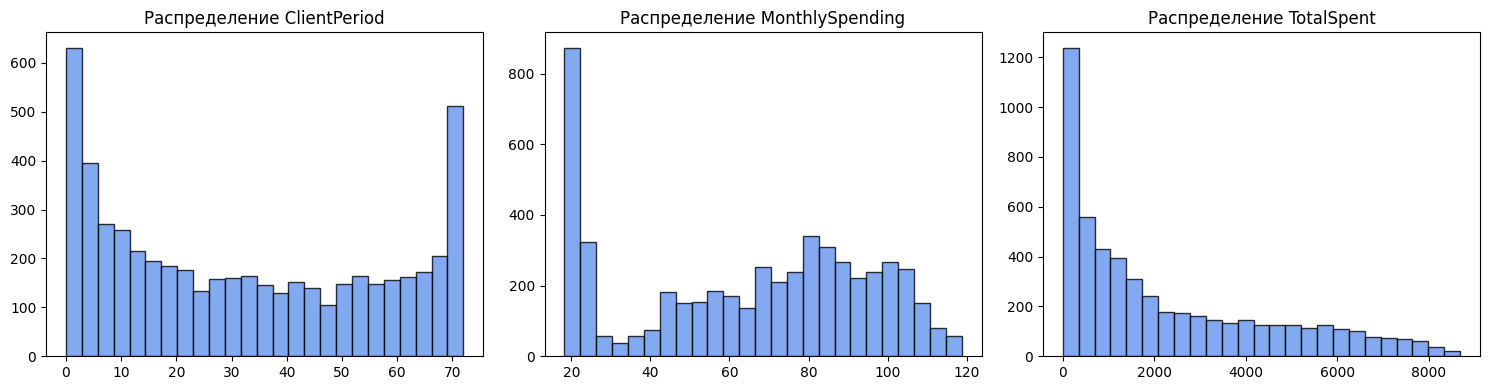

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
for i, j in enumerate(num_cols):
    axes[i].hist(data[j].dropna(), bins=25, color='cornflowerblue', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'Распределение {j}', fontsize=12)

plt.tight_layout()
plt.show()

Видим ассиметрию в данных у признака TotalSpent. Явных выбросов пока не вижу. Построим также boxplot для признаков, чтобы точнее увидеть, есть ли единичные выбросы

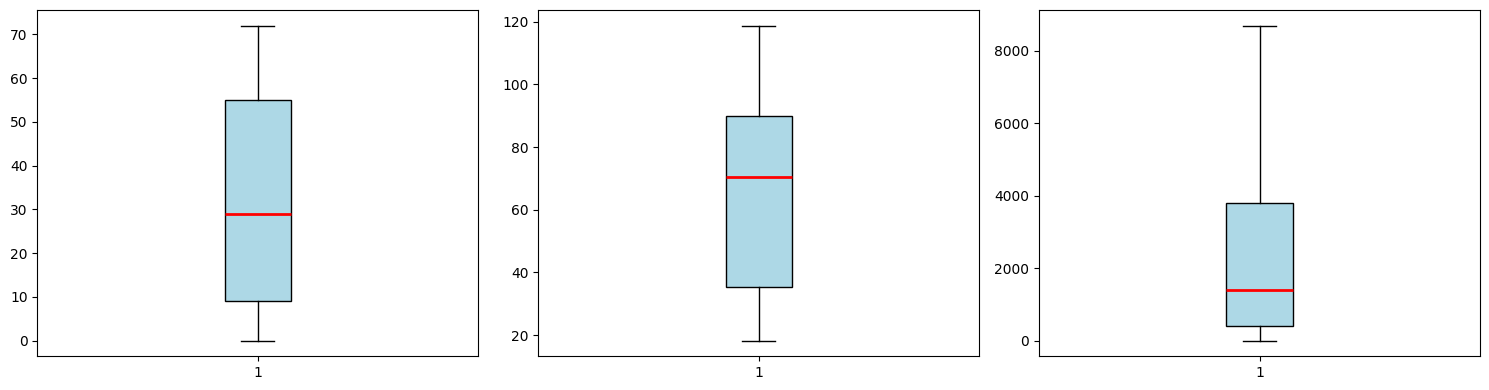

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))

for i, j in enumerate(num_cols):
    axes[i].boxplot(
        data[j].dropna(),
        patch_artist=True,
        boxprops=dict(facecolor='lightblue', color='black'),
        medianprops=dict(color='red', linewidth=2),
        flierprops=dict(marker='o', color='darkorange', alpha=0.5)
    )


plt.tight_layout()
plt.show()

Выбросов не наблюдается. Всё также можем увидеть ассиметрию в данных у признака TotalSpent. Переходим к предобработке и визуализации категориальных признаков

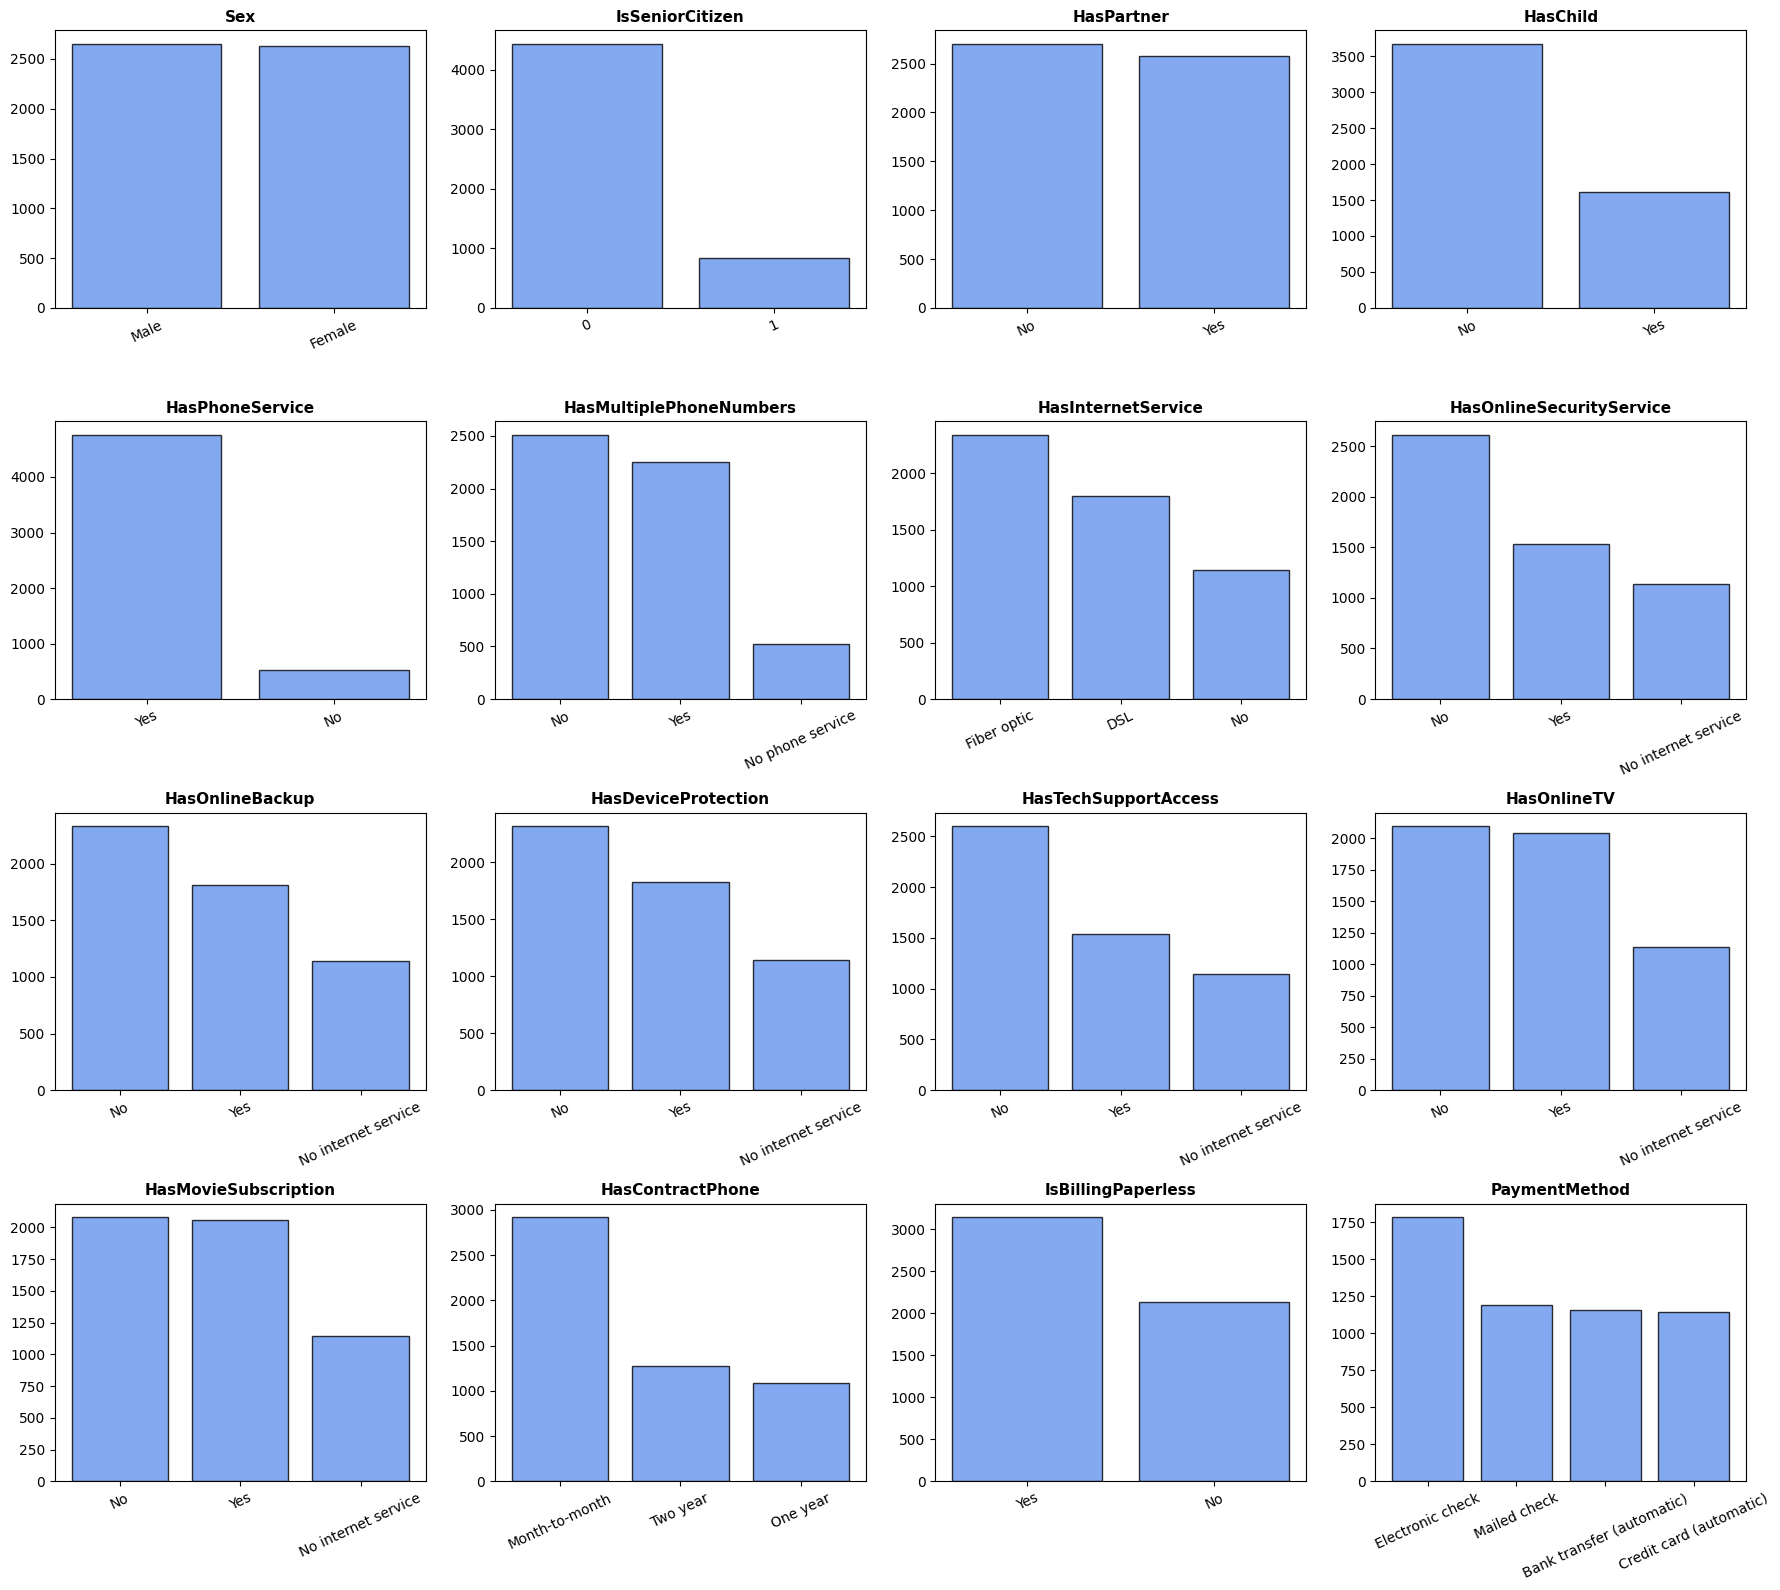

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i,j in enumerate(cat_cols):
  value_counts = data[j].value_counts()
  axes[i].bar(
      value_counts.index.astype(str),
      value_counts.values,
      color='cornflowerblue',
      edgecolor='black',
      alpha=0.8,
  )
  axes[i].set_title(j, fontsize=11, fontweight='bold')
  axes[i].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

Редкие категории и логические противоречия отсутствуют. Данные сбалансированы в соответствии с реальным распределением

## Применение логистической регрессии

In [ ]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder, OneHotEncoder
from sklearn.pipeline import make_pipeline

Переходим к обработке датасета. Сначала отделим целевую переменную, затем разделим тренировочный датасет на train/valid

In [ ]:
X = data[feature_cols]
y = data[target_col]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Отнормируем числовые признаки при помощи StandartScaler

In [ ]:
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[num_cols])
X_valid_num = scaler.transform(X_valid[num_cols])

Закондируем категориальные признаки при помощм One-Hot-Encoding

In [ ]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_valid_cat = encoder.transform(X_valid[cat_cols])

Склеиваю обработанные признаки обратно в одну таблицу. Создаю модель и настраиваю автоматический подбор гиперпараметров при помощи LogisticRegressionCV. Обучаю модель на train

In [ ]:
X_train_processed = np.hstack([X_train_num, X_train_cat])
X_valid_processed = np.hstack([X_valid_num, X_valid_cat])

clf = LogisticRegressionCV(
    Cs=[100, 10, 1, 0.1, 0.01, 0.001],
    cv=5,
    scoring='roc_auc',
    refit=True,
    max_iter=1000,
    random_state=42
).fit(X_train_processed, y_train)

Посмотрим визуально на влиятние разных значений гиперпараметра C на метрику ROC-AUC

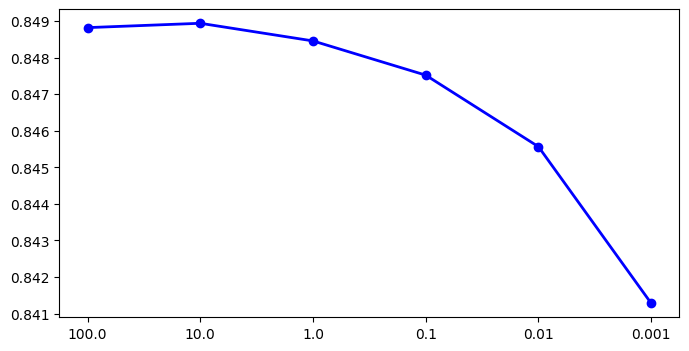

In [ ]:
mean_scores = clf.scores_[1].mean(axis=0)

plt.figure(figsize=(8, 4))
plt.plot(
    [str(c) for c in clf.Cs_], mean_scores, marker="o", color="b", linewidth=2
)

Визульно видим, что лучшим параметром оказался С = 10

In [ ]:
print(f"Лучший параметр C: {clf.C_[0]}")

Лучший параметр C: 10.0


Делаем предсказание на valid части

In [ ]:
valid_preds = clf.predict_proba(X_valid_processed)[:, 1]

In [ ]:
valid_preds

array([0.62617605, 0.27751332, 0.20211316, ..., 0.64002828, 0.01516573,
       0.01565389], shape=(1057,))

Считаем метрику ROC-AUC

In [ ]:
score = roc_auc_score(y_valid, valid_preds)
print("ROC-AUC:", score)

ROC-AUC: 0.8270287492727256


Лучшее качество (ROC-AUC: 0.8270287492727256) получили на C = 10.0. Остальные параметры входные (стандартные) и не менялись

## Применение градиентного бустинга

In [ ]:
#!pip install catboost
from catboost import CatBoostClassifier


Создаю саму модель со стандартными параметрами и обучаю её. train/valid части возьму с прошлого блока, чтобы не делить повторно.

In [ ]:
cat_boost_classificater  = CatBoostClassifier(random_state=42, verbose=0)
cat_boost_classificater.fit(X_train, y_train, cat_features=cat_cols)

CatBoostClassifier(random_state=42, verbose=0)

Делаем предсказание на валидационной части

In [ ]:
preds_cb = cat_boost_classificater.predict_proba(X_valid)[:, 1]
score_cb = roc_auc_score(y_valid, preds_cb)
print(score_cb)

0.821409111478468


Сейчас попробуем рассмотреть разные значения параметров. Буду использовать циклы для подбора лучших гиперпараметров. GridSearchCV не буду использовать. Также помимо количества деревьев и learning_rate'а добавлю L-2 регуляризацию и буду ограничивать глубину дерева

In [ ]:
learning_rates = [0.03, 0.1]
iterations_list = [100, 300, 500]
depth_list = [3, 4, 6]
l2_list = [3, 10, 20]

best_auc = 0
best_params = {}

for lr in learning_rates:
    for iters in iterations_list:
        for depth in depth_list:
            for l2 in l2_list:

                model = CatBoostClassifier(
                    learning_rate=lr,
                    iterations=iters,
                    depth=depth,
                    l2_leaf_reg=l2,
                    random_state=42,
                    verbose=0
                )

                model.fit(
                    X_train,
                    y_train,
                    cat_features=cat_cols
                )

                preds = model.predict_proba(X_valid)[:, 1]
                score = roc_auc_score(y_valid, preds)

                print(
                    f"lr={lr}, iterations={iters}, "
                    f"depth={depth}, l2={l2} | ROC-AUC={score:.5f}"
                )

                if score > best_auc:
                    best_auc = score
                    best_params = {
                        'learning_rate': lr,
                        'iterations': iters,
                        'depth': depth,
                        'l2_leaf_reg': l2
                    }

print("\nЛучшие параметры:",best_params)
print("Лучший ROC-AUC:", best_auc)

lr=0.03, iterations=100, depth=3, l2=3 | ROC-AUC=0.81957
lr=0.03, iterations=100, depth=3, l2=10 | ROC-AUC=0.81829
lr=0.03, iterations=100, depth=3, l2=20 | ROC-AUC=0.81810
lr=0.03, iterations=100, depth=4, l2=3 | ROC-AUC=0.82026
lr=0.03, iterations=100, depth=4, l2=10 | ROC-AUC=0.81627
lr=0.03, iterations=100, depth=4, l2=20 | ROC-AUC=0.81677
lr=0.03, iterations=100, depth=6, l2=3 | ROC-AUC=0.81859
lr=0.03, iterations=100, depth=6, l2=10 | ROC-AUC=0.81558
lr=0.03, iterations=100, depth=6, l2=20 | ROC-AUC=0.81078
lr=0.03, iterations=300, depth=3, l2=3 | ROC-AUC=0.83059
lr=0.03, iterations=300, depth=3, l2=10 | ROC-AUC=0.83051
lr=0.03, iterations=300, depth=3, l2=20 | ROC-AUC=0.83040
lr=0.03, iterations=300, depth=4, l2=3 | ROC-AUC=0.83073
lr=0.03, iterations=300, depth=4, l2=10 | ROC-AUC=0.83098
lr=0.03, iterations=300, depth=4, l2=20 | ROC-AUC=0.83115
lr=0.03, iterations=300, depth=6, l2=3 | ROC-AUC=0.82819
lr=0.03, iterations=300, depth=6, l2=10 | ROC-AUC=0.83114
lr=0.03, iterations=

Также проверим не слишком ли переобучается модель. Проверю метрику на train и сравню с метрикой на valid части

In [ ]:
best_model_boost = CatBoostClassifier(
    learning_rate=0.03,
    iterations=300,
    random_state=42,
    verbose=0,
    depth=4,
    l2_leaf_reg=20

)

best_model_boost.fit(
    X_train,
    y_train,
    cat_features=cat_cols
)
preds_train = best_model_boost.predict_proba(X_train)[:, 1]
preds_valid = best_model_boost.predict_proba(X_valid)[:, 1]

print("Train:", roc_auc_score(y_train, preds_train))
print("Valid:", roc_auc_score(y_valid, preds_valid))

Train: 0.8633467396642059
Valid: 0.8311545885243026


Всё в норме. Переобучения не наблюдаем)

Лучшее качество (ROC-AUC: 0.8311545885243026) при **lr** (шаг обучения) равном 0.03, **iterations**(количество итераций) равном 300, **l2_leaf_reg** (штраф за ошибку) равном 20 и **depth**(глубине дерева) равном 4

# Предсказания

In [ ]:
best_model = CatBoostClassifier(
    learning_rate=0.03,
    iterations=300,
    random_state=42,
    verbose=0,
    depth=4,
    l2_leaf_reg=20

)
best_model.fit(
    X_train,
    y_train,
    cat_features=cat_cols
)


CatBoostClassifier(depth=4, iterations=300, l2_leaf_reg=20, learning_rate=0.03, random_state=42, verbose=0)

In [ ]:
X_test = pd.read_csv('./test.csv')
submission = pd.read_csv('./submission.csv')

submission['Churn'] = best_model.predict_proba(X_test)[:, 1]
submission.to_csv('./my_submission.csv')

In [ ]:
submission.head(10)

,Id,Churn
0,0,0.047941
1,1,0.672305
2,2,0.670663
3,3,0.020896
4,4,0.008040
5,5,0.096238
6,6,0.435696
7,7,0.254034
8,8,0.064636
9,9,0.315254


Логистическая регрессия дала мне **ROC-AUC = 0.8459320363248554**, бустинг дал **ROC-AUC = 0.85217415893740** на тестовых данных. Так что оставлю CatBoostClassifier как лучшую модель